Ensemble Methods, Bias–Variance, Overfitting & Regularization


In [1]:


!pip -q install xgboost lightgbm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print("\nClass names:", list(data.target_names))
print("\nClass distribution:")
print(y.value_counts().sort_index())

display(X.head())

Dataset shape: (569, 30)

Class names: [np.str_('malignant'), np.str_('benign')]

Class distribution:
target
0    212
1    357
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Missing values:", X.isnull().sum().sum())
print("\nFeature statistics:")
display(X.describe().T.head(10))

Missing values: 0

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


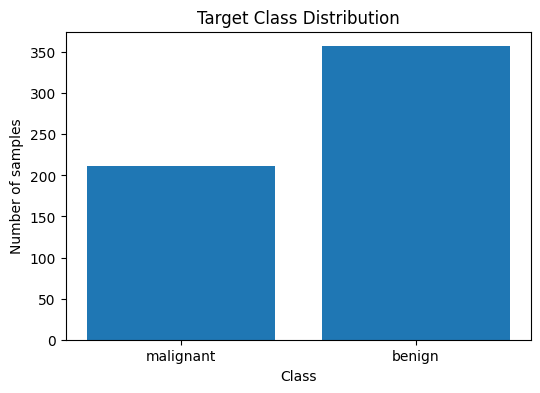

In [4]:
class_counts = y.value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(data.target_names, class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.title("Target Class Distribution")
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [6]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    result = {
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred),
        "Recall": recall_score(y_test, test_pred),
        "F1 Score": f1_score(y_test, test_pred)
    }

    return result, model

results = []
trained_models = {}

In [7]:
baseline_tree = DecisionTreeClassifier(random_state=42)

result, baseline_tree = evaluate_model("Decision Tree", baseline_tree)
results.append(result)
trained_models["Decision Tree"] = baseline_tree

pd.DataFrame([result])

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Decision Tree,1.0,0.912281,0.955882,0.902778,0.928571


In [8]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

result, rf = evaluate_model("Random Forest (Bagging)", rf)
results.append(result)
trained_models["Random Forest"] = rf

pd.DataFrame([result])

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Random Forest (Bagging),1.0,0.95614,0.958904,0.972222,0.965517


In [9]:
xgb = XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

result, xgb = evaluate_model("XGBoost", xgb)
results.append(result)
trained_models["XGBoost"] = xgb

pd.DataFrame([result])

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.997802,0.964912,0.959459,0.986111,0.972603


In [10]:
lgbm = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

result, lgbm = evaluate_model("LightGBM", lgbm)
results.append(result)
trained_models["LightGBM"] = lgbm

pd.DataFrame([result])

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,LightGBM,1.0,0.973684,0.972603,0.986111,0.97931


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Decision Tree,1.0000,0.9123,0.9559,0.9028,0.9286
1,Random Forest (Bagging),1.0000,0.9561,0.9589,0.9722,0.9655
2,XGBoost,0.9978,0.9649,0.9595,0.9861,0.9726
3,LightGBM,1.0000,0.9737,0.9726,0.9861,0.9793


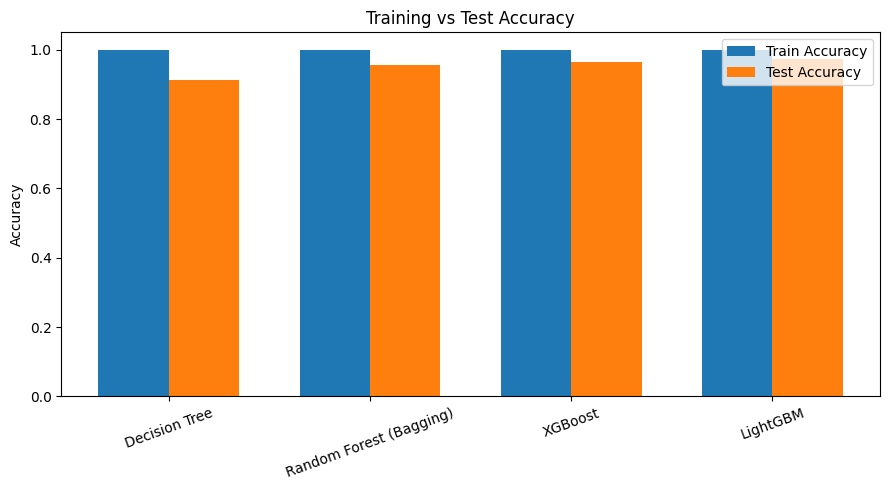

In [11]:
results_df = pd.DataFrame(results)
results_df = results_df.round(4)
display(results_df)

plt.figure(figsize=(9, 5))
x = np.arange(len(results_df))
width = 0.35

plt.bar(x - width/2, results_df["Train Accuracy"], width, label="Train Accuracy")
plt.bar(x + width/2, results_df["Test Accuracy"], width, label="Test Accuracy")

plt.xticks(x, results_df["Model"], rotation=20)
plt.ylabel("Accuracy")
plt.title("Training vs Test Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

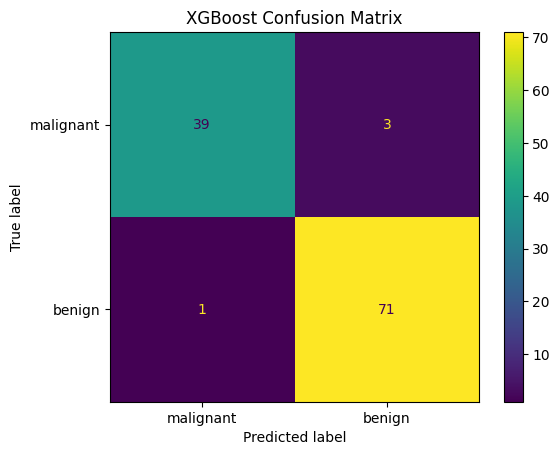

In [12]:
xgb_pred = xgb.predict(X_test)

cm = confusion_matrix(y_test, xgb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()

Bias–Variance and Overfitting Demonstration



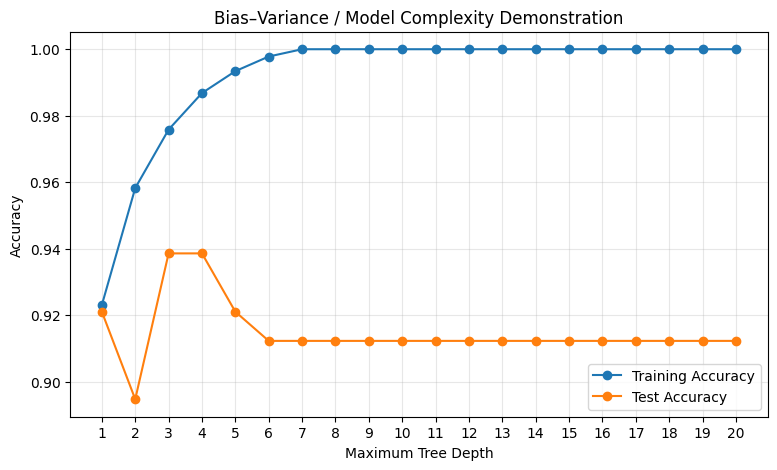

In [13]:
depths = range(1, 21)
train_scores = []
test_scores = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_scores, marker="o", label="Training Accuracy")
plt.plot(depths, test_scores, marker="o", label="Test Accuracy")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Bias–Variance / Model Complexity Demonstration")
plt.xticks(list(depths))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Interpretation

- At very low depth, both training and test performance can be limited → **underfitting / high bias**.
- As depth increases, the model can capture more patterns.
- At excessive depth, training accuracy may approach 100% while test accuracy stops improving or decreases → **overfitting / high variance**.

The exact depth at which this happens depends on the dataset.

L1 and L2 Regularization


In [15]:
l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l1",
        C=0.1,
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

l2_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l2",
        C=0.1,
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

l1_model.fit(X_train, y_train)
l2_model.fit(X_train, y_train)

l1_pred = l1_model.predict(X_test)
l2_pred = l2_model.predict(X_test)

regularization_results = pd.DataFrame({
    "Model": ["L1 Logistic Regression", "L2 Logistic Regression"],
    "Test Accuracy": [
        accuracy_score(y_test, l1_pred),
        accuracy_score(y_test, l2_pred)
    ],
    "Precision": [
        precision_score(y_test, l1_pred),
        precision_score(y_test, l2_pred)
    ],
    "Recall": [
        recall_score(y_test, l1_pred),
        recall_score(y_test, l2_pred)
    ],
    "F1 Score": [
        f1_score(y_test, l1_pred),
        f1_score(y_test, l2_pred)
    ]
})

display(regularization_results.round(4))

,Model,Test Accuracy,Precision,Recall,F1 Score
0,L1 Logistic Regression,0.9561,0.9718,0.9583,0.9650
1,L2 Logistic Regression,0.9825,0.9861,0.9861,0.9861


In [16]:
l1_coef = l1_model.named_steps["classifier"].coef_[0]
l2_coef = l2_model.named_steps["classifier"].coef_[0]

coef_comparison = pd.DataFrame({
    "Feature": X.columns,
    "L1 Coefficient": l1_coef,
    "L2 Coefficient": l2_coef
})

print("Number of exactly-zero L1 coefficients:",
      np.sum(np.isclose(l1_coef, 0)))

display(coef_comparison.sort_values(
    by="L1 Coefficient",
    key=lambda s: np.abs(s),
    ascending=False
).head(15))

Number of exactly-zero L1 coefficients: 22


,Feature,L1 Coefficient,L2 Coefficient
20,worst radius,-2.122532,-0.515598
27,worst concave points,-0.943057,-0.496777
21,worst texture,-0.575617,-0.548639
7,mean concave points,-0.500713,-0.413799
10,radius error,-0.431542,-0.459034
24,worst smoothness,-0.206336,-0.390018
28,worst symmetry,-0.173980,-0.405547
1,mean texture,-0.049188,-0.428021
8,mean symmetry,0.000000,-0.153083
4,mean smoothness,0.000000,-0.175088


Regularization Strength Experiment


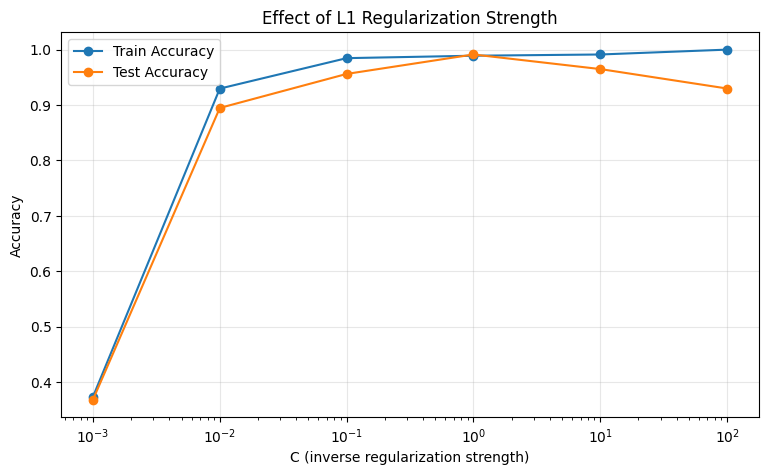

In [17]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
l1_train = []
l1_test = []

for C in C_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            penalty="l1",
            C=C,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    l1_train.append(model.score(X_train, y_train))
    l1_test.append(model.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.semilogx(C_values, l1_train, marker="o", label="Train Accuracy")
plt.semilogx(C_values, l1_test, marker="o", label="Test Accuracy")

plt.xlabel("C (inverse regularization strength)")
plt.ylabel("Accuracy")
plt.title("Effect of L1 Regularization Strength")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 14. Final Observations

1. **Bagging** combines independently trained models and mainly helps reduce variance.
2. **Random Forest** is a common bagging ensemble based on decision trees.
3. **Boosting** trains weak learners sequentially so later learners improve the current model.
4. **XGBoost** and **LightGBM** are powerful gradient-boosting frameworks.
5. **Underfitting** is associated with a model that is too simple and has high bias.
6. **Overfitting** occurs when the model fits training data too closely and generalizes poorly.
7. **L1 regularization** can create sparse models by driving some coefficients to zero.
8. **L2 regularization** shrinks coefficients and discourages excessive parameter magnitude.
9. The best model should be judged using validation/test performance and the requirements of the particular problem, not training accuracy alone.